# Short-Term Hydropower Scheduling and Unit Commitment

## What this project is about:
We are working on short-term hydropower planning for the **Tokke-Vinje** watercourse system in southern Norway (which has 17 reservoirs, 9 power plants, and 14 generating units). The main goal is to build a Machine Learning model that predicts whether generating units should be turned on or off (*Unit Commitment - UC*) over a one-week horizon (168 hours). The idea is to help speed up and improve the heavy optimization methods usually required for this.

## What I did in this notebook:
- **Set up paths and structure:** Organized the folders to cleanly separate the core datasets from the extended constraints and topologies.
- **Loaded all the data:** Brought in everything we need, from hourly market prices and reservoir inflows to daily storage levels, water values, system constraints, and the ground-truth unit commitment decisions
- **Checked data shapes and heads:** Did a quick exploratory run to inspect the dimensions and first rows of each dataset, making sure timestamps, units, and structures are all in order before moving on to feature engineering and modeling.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

#Configure display options for pandas and seaborn
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

### 1. Data Loading and Structure Verification
First, we set up our file paths to distinguish between the kernel datasets (core time series and target variables) and the extended datasets (topologies and constraints)

In [4]:
BASE_PATH = Path(".")
KERNEL_PATH = BASE_PATH / "data" / "kernel"
EXTENDED_PATH = BASE_PATH / "data" / "extended"

#Load core datasets
price = pd.read_csv(KERNEL_PATH / "Historical_day_ahead_price_2015_2025.csv")
inflow = pd.read_csv(KERNEL_PATH / "Historical_inflow_1958_2025.csv")
volume = pd.read_csv(KERNEL_PATH / "Historical_volume_2015_2024.csv")
water_value = pd.read_csv(KERNEL_PATH / "Synthetic_water_value_2015_2024.csv")

#Load extended datasets (constraints)
min_volume = pd.read_csv(EXTENDED_PATH / "Constraint_min_volume.csv")
min_flow = pd.read_csv(EXTENDED_PATH / "Constraint_min_flow.csv")

#Load target variable (Unit Commitment decisions)
uc = pd.read_csv(KERNEL_PATH / "Unit_commitment_decisions.csv")

### 2. Exploratory Data Analysis (EDA): Dataset Shapes

Inspect the dimensions of each dataset to understand their scale and temporal granularity (hourly vs. daily data).

In [5]:
datasets = {
    "Price": price,
    "Inflow": inflow,
    "Volume": volume,
    "Water value": water_value,
    "Minimum volume": min_volume,
    "Minimum flow": min_flow,
    "Unit commitment": uc
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Price: (103062, 2)
Inflow: (594224, 19)
Volume: (3654, 18)
Water value: (3654, 18)
Minimum volume: (96432, 4)
Minimum flow: (96432, 7)
Unit commitment: (2922, 2355)


### 3. Data Head Inspection

A quick look at the first few rows of the primary datasets gives us an idea of the features, timestamp formatting, and unit structures.

In [6]:
print("--- Day-ahead Price ---")
display(price.head())

print("--- Reservoir Inflow ---")
display(inflow.head())

print("--- Reservoir Storage (Volume) ---")
display(volume.head())

print("--- Synthetic Water Value ---")
display(water_value.head())

print("--- Unit Commitment Decisions (Target Preview) ---")
display(uc.head())

--- Day-ahead Price ---


,date,Day-ahead price (EUR/MWh)
0,2015-01-01 00:00:00+00:00,27.07
1,2015-01-01 01:00:00+00:00,26.93
2,2015-01-01 02:00:00+00:00,26.83
3,2015-01-01 03:00:00+00:00,26.81
4,2015-01-01 04:00:00+00:00,26.97


--- Reservoir Inflow ---


,date,Langesae,Staavatn,Kjelavatn,Bordalsvatn,Foersvatn,Hyljelihyl,Venemo,Bitdalsvatn,Songavatn,Totak,Vaamarvatn,Langeidvatn,Vatjern,Vinjevatn,Botnedalsvatn,Byrtevatn,Bandak,r_Vest_Vassdraget
0,1958-01-01 00:00:00+00:00,0.37,0.03,1.23,0.5,0.05,0.34,0.37,1.07,4.92,3.28,0.21,0.18,0.02,4.49,0.56,0.42,2.68,0.56
1,1958-01-01 01:00:00+00:00,0.37,0.03,1.23,0.5,0.05,0.34,0.37,1.07,4.92,3.28,0.21,0.18,0.02,4.49,0.56,0.42,2.68,0.56
2,1958-01-01 02:00:00+00:00,0.37,0.03,1.23,0.5,0.05,0.34,0.37,1.07,4.92,3.28,0.21,0.18,0.02,4.49,0.56,0.42,2.68,0.56
3,1958-01-01 03:00:00+00:00,0.37,0.03,1.23,0.5,0.05,0.34,0.37,1.07,4.92,3.28,0.21,0.18,0.02,4.49,0.56,0.42,2.68,0.56
4,1958-01-01 04:00:00+00:00,0.37,0.03,1.23,0.5,0.05,0.34,0.37,1.07,4.92,3.28,0.21,0.18,0.02,4.49,0.56,0.42,2.68,0.56


--- Reservoir Storage (Volume) ---


,date,Kjelavatn,Staavatn,Langesae,Foersvatn,Venemo,Botnedalsvatn,Bitdalsvatn,Vaamarvatn,Langeidvatn,Totak,Songavatn,Vinjevatn,Bandak,Bordalsvatn,Byrtevatn,Hyljelihyl,Vatjern
0,2015-01-01 00:00:00+00:00,42.352,17.472,56.669,92.150,18.263,32.999,92.404,9.796,30.541,170.219,492.379,6.672,137.785,166.063,63.929,0.13,0.15
1,2015-01-02 00:00:00+00:00,42.001,16.474,56.262,92.185,18.332,32.999,92.024,11.079,30.587,170.219,489.891,5.959,137.785,165.969,63.884,0.13,0.15
2,2015-01-03 00:00:00+00:00,41.494,15.360,55.753,92.079,18.356,32.743,91.786,12.257,30.587,170.219,487.126,6.445,137.785,165.733,63.703,0.13,0.15
3,2015-01-04 00:00:00+00:00,41.221,14.784,55.516,91.938,18.388,32.589,91.453,11.425,30.541,169.512,485.468,6.996,137.785,165.591,63.568,0.13,0.15
4,2015-01-05 00:00:00+00:00,41.182,14.630,55.482,91.903,18.388,32.538,91.025,10.143,30.541,169.512,485.191,7.028,137.785,165.544,63.522,0.13,0.15


--- Synthetic Water Value ---


,date,Kjelavatn,Staavatn,Langesae,Foersvatn,Venemo,Botnedalsvatn,Bitdalsvatn,Vaamarvatn,Langeidvatn,Totak,Songavatn,Vinjevatn,Bandak,Bordalsvatn,Byrtevatn,Hyljelihyl,Vatjern
0,2015-01-01 00:00:00+00:00,40.49,40.49,31.81,31.81,28.98,38.70,30.13,28.98,4.78,28.98,30.13,22.65,7.73,31.81,9.32,28.98,4.78
1,2015-01-02 00:00:00+00:00,40.89,40.89,30.96,30.96,26.44,36.47,30.52,26.44,4.44,26.44,30.52,35.13,8.52,30.96,8.72,26.44,4.44
2,2015-01-03 00:00:00+00:00,40.87,40.87,30.51,30.51,26.36,36.35,30.39,26.36,4.28,26.36,30.39,35.30,10.18,30.51,8.43,26.36,4.28
3,2015-01-04 00:00:00+00:00,40.50,40.50,30.06,30.06,26.33,35.68,30.11,26.33,4.23,26.33,30.11,28.63,7.16,30.06,7.96,26.33,4.23
4,2015-01-05 00:00:00+00:00,39.51,39.51,29.35,29.35,26.06,34.59,29.58,26.06,3.89,26.06,29.58,31.33,3.14,29.35,7.40,26.06,3.89


--- Unit Commitment Decisions (Target Preview) ---


Run No   starttime  total_calculation_time  result_committed_Hogga_G1_t0  \
0       1  2015-01-01               48.950692                             1   
1       2  2015-01-02               56.048899                             1   
2       3  2015-01-03               44.280307                             1   
3       4  2015-01-04               40.848453                             1   
4       5  2015-01-05               44.036279                             1   

   result_committed_Hogga_G1_t1  result_committed_Hogga_G1_t2  \
0                             1                             1   
1                             1                             1   
2                             1                             1   
3                             1                             1   
4                             1                             1   

   result_committed_Hogga_G1_t3  result_committed_Hogga_G1_t4  \
0                             1                             1   
1                             1                             1   
2                             1                             1   
3                             1                             1   
4                             1                             1   

   result_committed_Hogga_G1_t5  result_committed_Hogga_G1_t6  \
0                             1                             1   
1                             1                             1   
2                             1                             1   
3                             1                             1   
4                             1                             1   

   result_committed_Hogga_G1_t7  result_committed_Hogga_G1_t8  \
0                             1                             1   
1                             1                             1   
2                             1                             1   
3                             1                             1   
4                             1                             1   

   result_committed_Hogga_G1_t9  result_committed_Hogga_G1_t10  \
0                             1                              1   
1                             1                              1   
2                             1                              1   
3                             1                              1   
4                             1                              1   

   result_committed_Hogga_G1_t11  result_committed_Hogga_G1_t12  \
0                              1                              1   
1                              1                              1   
2                              1                              1   
3                              1                              1   
4                              1                              1   

   result_committed_Hogga_G1_t13  result_committed_Hogga_G1_t14  \
0                              1                              1   
1                              1                              1   
2                              1                              1   
3                              1                              1   
4                              1                              1   

   result_committed_Hogga_G1_t15  result_committed_Hogga_G1_t16  \
0                              1                              1   
1                              1                              1   
2                              1                              1   
3                              1                              1   
4                              1                              1   

   result_committed_Hogga_G1_t17  result_committed_Hogga_G1_t18  \
0                              1                              1   
1                              1                              1   
2                              1                              1   
3                              1                              1   
4                      

### 4. Data Quality: Missing Values and Duplicates

Check data quality, specifically missing values and duplicate rows across our main dataframes.

In [7]:
def check_data_quality(df_dict):
    quality_report = []
    for name, df in df_dict.items():
        missing_count = df.isnull().sum().sum()
        duplicate_count = df.duplicated().sum()
        quality_report.append({
            "Dataset": name,
            "Total Missing Values": missing_count,
            "Duplicate Rows": duplicate_count
        })
    return pd.DataFrame(quality_report)

quality_df = check_data_quality(datasets)
display(quality_df)

,Dataset,Total Missing Values,Duplicate Rows
0,Price,0,0
1,Inflow,0,0
2,Volume,0,0
3,Water value,0,0
4,Minimum volume,0,0
5,Minimum flow,0,0
6,Unit commitment,0,0


## Data Quality Overview

* **Completeness & Uniqueness:** All core and extended datasets (Price, Inflow, Volume, Water value, Minimum volume, Minimum flow, and Unit commitment) are fully clean, containing **0 missing values** and **0 duplicate rows**, ensuring high data reliability for modeling.

### 5. Statistical Summary 

To understand the statistical distribution, scale, and general tendencies of our numerical features (prices, inflows, volumes, and water values), we generate descriptive statistics for all main datasets together below.

In [8]:
# Display summary statistics for each core dataset
for name, df in datasets.items():
    print(f"==================================================")
    print(f" DESCRIBE STATISTICS: {name}")
    print(f"==================================================")
    display(df.describe())
    print("\n")

 DESCRIBE STATISTICS: Price


,Day-ahead price (EUR/MWh)
count,103062.000000
mean,59.492173
std,67.356150
min,-61.840000
25%,25.360000
50%,40.770000
75%,69.080000
max,898.250000




 DESCRIBE STATISTICS: Inflow


,Langesae,Staavatn,Kjelavatn,Bordalsvatn,Foersvatn,Hyljelihyl,Venemo,Bitdalsvatn,Songavatn,Totak,Vaamarvatn,Langeidvatn,Vatjern,Vinjevatn,Botnedalsvatn,Byrtevatn,Bandak,r_Vest_Vassdraget
count,594224.000000,594224.000000,594224.000000,594224.000000,594224.000000,594224.000000,594224.000000,594224.000000,594224.000000,594224.000000,594224.000000,594224.000000,594224.000000,594224.000000,594224.000000,594224.000000,594224.000000,594224.000000
mean,1.791184,6.230031,3.205070,5.731122,0.597858,3.891250,1.963224,5.184187,23.874400,9.738917,0.639237,2.096779,0.214025,13.345239,6.520667,4.842390,17.507385,6.451834
std,2.541559,9.061160,3.451059,9.967011,1.039733,6.767195,3.480303,7.356104,33.876526,13.834582,0.907659,3.646334,0.372250,18.957593,11.340004,8.421462,27.998786,11.220469
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.010000,0.170000,0.010000,0.000000,0.000000,0.240000,0.000000,0.000000,0.010000,0.000000
25%,0.270000,0.360000,0.760000,0.630000,0.070000,0.430000,0.290000,0.780000,3.610000,2.260000,0.150000,0.230000,0.020000,3.090000,0.720000,0.540000,3.030000,0.710000
50%,0.800000,1.840000,1.690000,2.110000,0.220000,1.430000,0.710000,2.310000,10.630000,4.650000,0.300000,0.770000,0.080000,6.370000,2.400000,1.780000,7.330000,2.380000
75%,2.130000,8.910000,4.600000,6.190000,0.650000,4.200000,1.890000,6.170000,28.390000,10.930000,0.720000,2.260000,0.230000,14.980000,7.040000,5.230000,18.950000,6.970000
max,22.930000,102.430000,21.510000,415.760000,43.370000,282.280000,145.770000,66.370000,305.640000,150.590000,9.880000,152.100000,15.530000,206.360000,473.030000,351.290000,636.810000,468.040000




 DESCRIBE STATISTICS: Volume


...

,Totak,Byrtevatn,Staavatn
count,96432.000000,96432.000000,96432.000000
mean,68.160342,8.522788,11.878817
std,95.207190,22.453597,20.325257
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,194.233000,0.000000,46.656000
max,211.890000,67.677000,46.656000




 DESCRIBE STATISTICS: Minimum flow


,b_Kjelavatn,b_Hyljelihyl,b_Vinjevatn,b_Byrtevatn,b_Bandak,r_Vest_Vassdraget
count,96432.000000,96432.000000,96432.000000,96432.000000,96432.000000,96432.000000
mean,0.469353,1.064647,1.418865,0.067894,4.418865,7.275012
std,0.211576,0.705255,0.493376,0.094707,0.493376,3.288650
min,0.300000,0.500000,1.000000,0.000000,4.000000,5.000000
25%,0.300000,0.500000,1.000000,0.000000,4.000000,5.000000
50%,0.300000,0.500000,1.000000,0.000000,4.000000,5.000000
75%,0.750000,2.000000,2.000000,0.200000,5.000000,8.000000
max,0.750000,2.000000,2.000000,0.200000,5.000000,14.000000




 DESCRIBE STATISTICS: Unit commitment


Run No  total_calculation_time  result_committed_Hogga_G1_t0  \
count  2922.000000             2922.000000                   2922.000000   
mean   1461.500000              147.018996                      0.558179   
std     843.653069              333.067145                      0.496689   
min       1.000000               22.406436                      0.000000   
25%     731.250000               39.995748                      0.000000   
50%    1461.500000               51.737313                      1.000000   
75%    2191.750000               78.254212                      1.000000   
max    2922.000000             4525.742015                      1.000000   

       result_committed_Hogga_G1_t1  result_committed_Hogga_G1_t2  \
count                   2922.000000                   2922.000000   
mean                       0.558179                      0.557837   
std                        0.496689                      0.496729   
min                        0.000000                      0.000000   
25%                        0.000000                      0.000000   
50%                        1.000000                      1.000000   
75%                        1.000000                      1.000000   
max                        1.000000                      1.000000   

       result_committed_Hogga_G1_t3  result_committed_Hogga_G1_t4  \
count                   2922.000000                   2922.000000   
mean                       0.561602                      0.581451   
std                        0.496276                      0.493406   
min                        0.000000                      0.000000   
25%                        0.000000                      0.000000   
50%                        1.000000                      1.000000   
75%                        1.000000                      1.000000   
max                        1.000000                      1.000000   

       result_committed_Hogga_G1_t5  result_committed_Hogga_G1_t6  \
count                   2922.000000                   2922.000000   
mean                       0.604038                      0.623546   
std                        0.489140                      0.484579   
min                        0.000000                      0.000000   
25%                        0.000000                      0.000000   
50%                        1.000000                      1.000000   
75%                        1.000000                      1.000000   
max                        1.000000                      1.000000   

       result_committed_Hogga_G1_t7  result_committed_Hogga_G1_t8  \
count                   2922.000000                   2922.000000   
mean                       0.627995                      0.621492   
std                        0.483423                      0.485098   
min                        0.000000                      0.000000   
25%                        0.000000                      0.000000   
50%                        1.000000                      1.000000   
75%                        1.000000                      1.000000   
max                        1.000000                      1.000000   

       result_committed_Hogga_G1_t9  result_committed_Hogga_G1_t10  \
count                   2922.000000                    2922.000000   
mean                       0.615674                       0.608487   
std                        0.486519                       0.488172   
min                        0.000000                       0.000000   
25%                        0.000000                       0.000000   
50%                        1.000000                       1.000000   
75%                        1.000000                       1.000000   
max                        1.000000                       1.000000   

       result_committed_Hogga_G1_t11  result_committed_Hogga_G1_t12  \
count                    2922.000000                    2922.000000   
mean                        0.604038                       0.60472

## Statistical Summary Overview

* **Price:** Averages 59.49 EUR/MWh with high volatility, ranging from negative oversupply prices (-61.84) to extreme crisis peaks (898.25)
* **Inflow:** Right-skewed water inflows across 17 reservoirs and rivers, with peak events driven by seasonal melting or precipitation (e.g., r_Vest_Vassdraget up to 468.04 m3/s)
* **Volume:** Initial daily storage across reservoirs; major capacities reside in large basins like Songavatn, while minor unrecorded basins (Hyljelihyl, Vatjern) assume a 50% full baseline
* **Water Value:** Marginal future water values average 67.01 EUR/MWh with heavy upper tails exceeding 1,200 EUR/MWh, guiding generation strategies
* **Minimum Volume:** Constraints are enforced only on select reservoirs (Totak, Byrtevatn, Staavatn), defaulting to 0 elsewhere
* **Minimum Flow:** Mandatory ecological flow requirements apply to six rivers, led by r_Vest_Vassdraget averaging 7.28 m3/s
* **Unit Commitment:** Binary target decisions (0/1) across 2,922 rolling weekly cases, showing a balanced active/inactive schedule for generating units

### 6. Exploratory Data Analysis: Visualizations

Visualize:
1. The evolution of Day-ahead electricity prices over time.
2. A correlation heatmap of reservoir inflows.
3. The distribution of electricity prices.

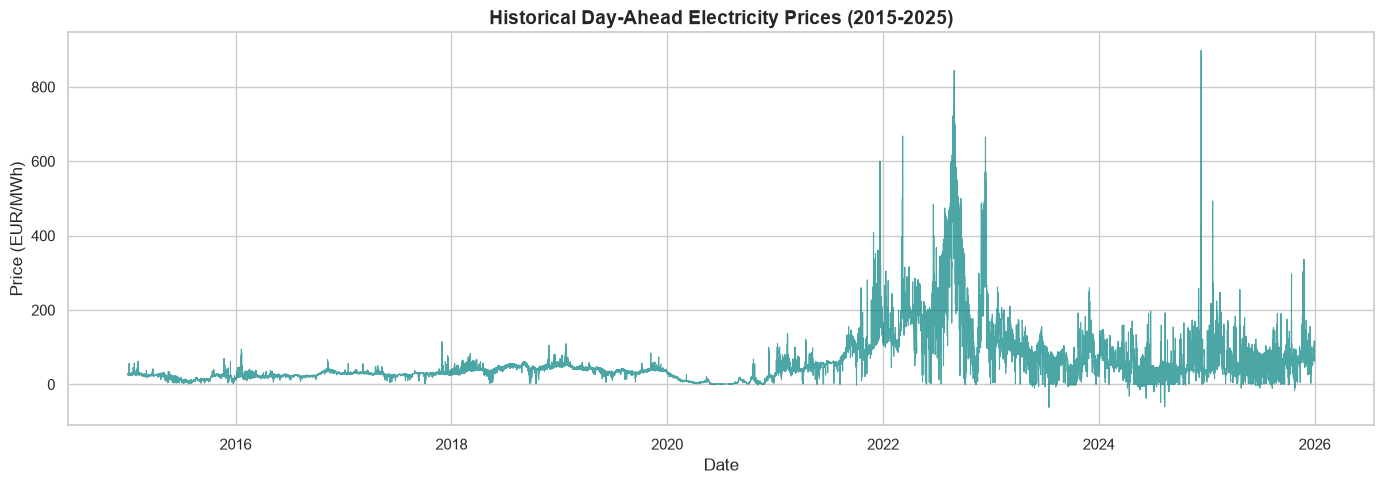

In [9]:
# 1.Time Series: Day-ahead Price over time
#we convert the 'date' column to datetime and set it as index for easy plotting
price['date'] = pd.to_datetime(price['date'])
price_sorted = price.sort_values('date')

plt.figure(figsize=(14, 5))
plt.plot(price_sorted['date'], price_sorted['Day-ahead price (EUR/MWh)'], color='teal', alpha=0.7, linewidth=0.8)
plt.title('Historical Day-Ahead Electricity Prices (2015-2025)', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price (EUR/MWh)', fontsize=12)
plt.tight_layout()
plt.show()

* **Explanation:** This time series plot illustrates the hourly evolution of day-ahead electricity market prices over a decade. It highlights long-term stability prior to 2021, followed by extreme price volatility and significant spikes during the 2022 energy crisis.

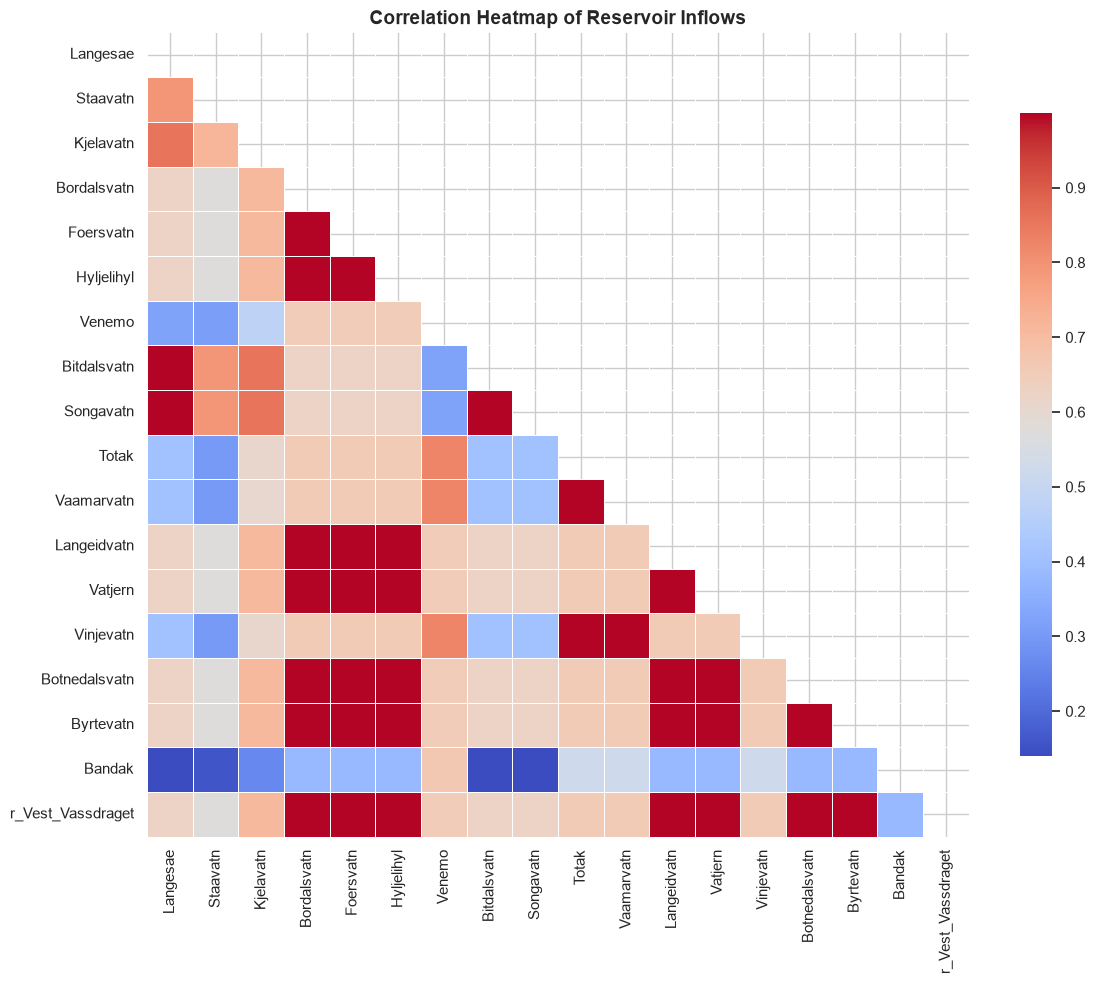

In [11]:
#2.Correlation Heatmap: Reservoir Inflows
plt.figure(figsize=(12, 10))
inflow_numeric = inflow.drop(columns=['date'], errors='ignore')
corr_matrix = inflow_numeric.corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=False, cmap='coolwarm', fmt=".2f", linewidths=0.5, cbar_kws={'shrink': .8})
plt.title('Correlation Heatmap of Reservoir Inflows', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

* **Explanation:** This heatmap displays the linear correlation coefficients between water inflows across different reservoirs. High correlation values indicate reservoirs influenced by similar weather patterns or geographic proximity, while lower correlations point to independent catchment areas.

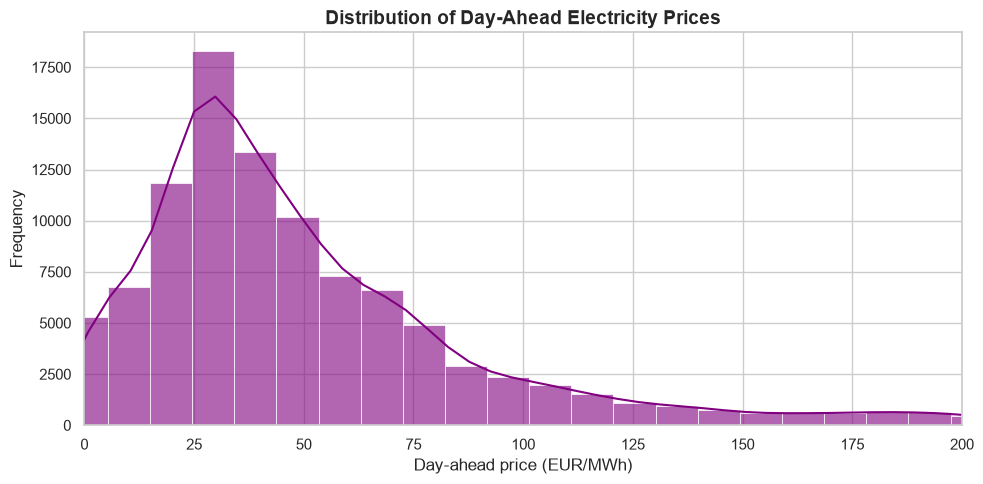

In [12]:
#3. Price Distribution: Histogram & KDE
plt.figure(figsize=(10, 5))
sns.histplot(price['Day-ahead price (EUR/MWh)'], bins=100, kde=True, color='purple', alpha=0.6)
plt.title('Distribution of Day-Ahead Electricity Prices', fontsize=14, fontweight='bold')
plt.xlabel('Day-ahead price (EUR/MWh)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.xlim(0, 200)  # Limiting x-axis to zoom in on typical price ranges, avoiding extreme outliers
plt.tight_layout()
plt.show()

* **Explanation:** This histogram and KDE curve show the statistical distribution of electricity prices (restricted to 0–200 EUR/MWh for clarity). The distribution is right-skewed, showing that prices most frequently concentrate between 25 and 35 EUR/MWh, while high-price spikes act as long-tail outliers.